In [2]:
%matplotlib widget
import os
import numpy as np
import pandas as pd
import glob2 as gb
import glob
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch
import time
from sklearn.preprocessing import MaxAbsScaler

mpl.rcParams['keymap.pan'] = ['d']
mpl.rcParams['keymap.zoom'] = ['z']


In [3]:
cwd = os.getcwd()
phase_name = 'alpha'

perturb_dirs = [cwd, 'TOPAS', phase_name, 'ml_data_generation','randomstates']
expt_dirs =  [cwd, 'TOPAS', phase_name, 'experimental_refinement']
pawley_dirs = [cwd, 'TOPAS', phase_name, 'subgrouptree_refinement']

bin_edges_filename = f'{phase_name}_bin_edges_C0p0008.txt'
expt_hkl_filename = 'd_Ip_expt_VC_P1_latparams.dat'
expt_xy_filename = 'simulated_xy_expt_VC_P1_latparams.xy'

perturb_path = os.path.join(*perturb_dirs)
expt_path = os.path.join(*expt_dirs)
pawley_path = os.path.join(*pawley_dirs)

# load bin edges
bin_edges_path = os.path.join(cwd, 'TOPAS', phase_name, 'alpha_bin_edges_C0p0008.txt')
bin_edges = torch.tensor(np.loadtxt(bin_edges_path))

# -------------------------------------------------------------------------------------------
# get xy data functions
# -------------------------------------------------------------------------------------------
def get_expt_xy(expt_path):
    expt_file = os.path.join(expt_path, expt_xy_filename)
    expt_xy = pd.read_csv(expt_file, sep='\s+', header = None, names = ['x','y'])
    return expt_xy

def get_xy_pawley(pawley_path, cifnumber):
    xy_path = os.path.join(pawley_path, f'cif{cifnumber}', f'cif{cifnumber}_xy.xy')
    xy = pd.read_csv(xy_path, sep='\s+', header = None, names = ['x','y'])
    return xy

def get_xy_perturb(perturb_path, cifnumber, statenumber):
    xy_path = os.path.join(perturb_path, f'cif{cifnumber}_randomstates', f'cif{cifnumber}_rs_{statenumber}_xy.xy')
    xy = pd.read_csv(xy_path, sep='\s+', header = None, names = ['x','y'])
    return xy

# -------------------------------------------------------------------------------------------
# get hkl data functions
# -------------------------------------------------------------------------------------------

def get_expt_hkl(expt_path, bin_edges, scale=None):
    expt_file = os.path.join(expt_path, expt_hkl_filename)
    hkl = pd.read_csv(expt_file, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_binned = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_binned

def get_hkl_pawley(pawley_path, cifnumber, bin_edges, scale=None):
    hkl_path = os.path.join(pawley_path, f'cif{cifnumber}', f'cif{cifnumber}_hkl.dat')
    hkl = pd.read_csv(hkl_path, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_binned = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_binned

def get_hkl_perturb(perturb_path, cifnumber, statenumber, bin_edges, scale=None):
    hkl_path = os.path.join(perturb_path, f'cif{cifnumber}_randomstates', f'cif{cifnumber}_rs_{statenumber}_hkl.dat')
    hkl = pd.read_csv(hkl_path, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_tensor = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_tensor

# -------------------------------------------------------------------------------------------
# modify hkl data functions
# -------------------------------------------------------------------------------------------

def bin_tensor(tensor_to_bin, bin_edges, scale):
    binned_tensor = torch.zeros_like(bin_edges)
    bucket_tensor = torch.bucketize(tensor_to_bin[:,0], bin_edges, right=False)
    for index,value in zip(bucket_tensor, tensor_to_bin[:,1]):
        binned_tensor[index] += value

    if scale != None:
        if scale == 'minmax':
            binned_scaled_tensor = minmaxscale_tensor(binned_tensor)
            return binned_scaled_tensor
        # if scale == 'maxabs':
        #     binned_scaled_tensor = maxabsscale_tensor(binned_tensor)
        #     return binned_scaled_tensor
        # if scale == 'minmax_maxabs':
        #     binned_scaled_tensor = minmax_maxabs_tensor(binned_tensor)
        #     return binned_scaled_tensor

    return binned_tensor

def minmaxscale_tensor(tensor):
    # Find the minimum and maximum values in the tensor
    min_val = torch.min(tensor)
    max_val = torch.max(tensor)
    # print(min_val)
    # print(max_val)
    # Scale the tensor to the range [0, 1]
    scaled_tensor = (tensor - min_val) / (max_val - min_val)
    
    return scaled_tensor

def maxabsscale_tensor(binned_tensor_list):
    local_data = torch.vstack(binned_tensor_list)
    scale_data = local_data.numpy()
    transformer = MaxAbsScaler().fit(scale_data)
    data_scaled = transformer.transform(scale_data)
    data_scaled_tensor = torch.tensor(data_scaled)
    scaled_tensor_list = list(data_scaled_tensor)
    return scaled_tensor_list
    


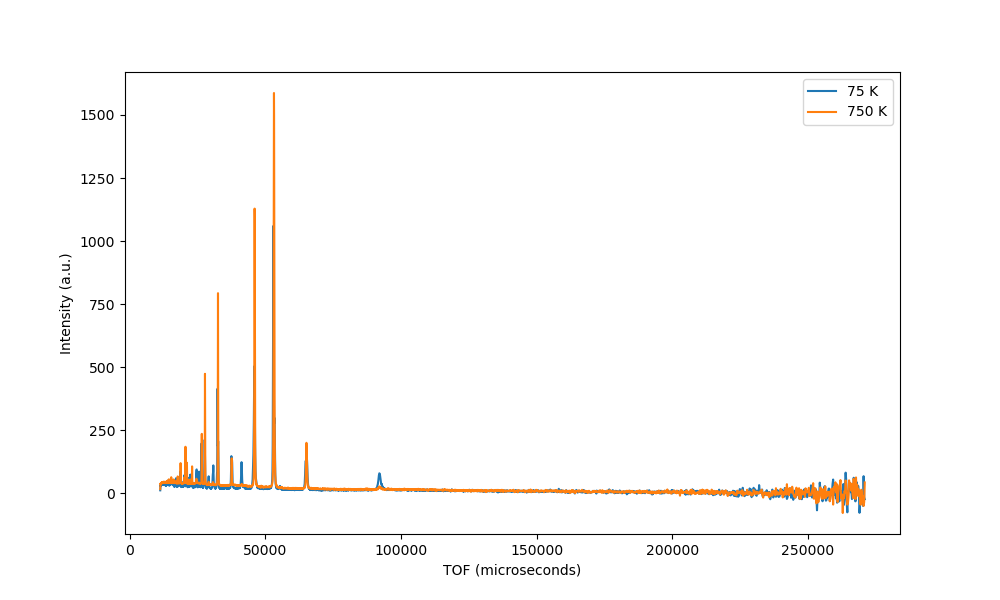

In [5]:

expt_path = 'C:/Users/dx6/Desktop/RESEARCH/PZT/pzt_powgen_data/PZT_45'
pzt_75k_file = glob.glob(f'{expt_path}/PZT_45_75_K.xye')[0]
pzt_750k_file = glob.glob(f'{expt_path}/PZT_45_750_K.xye')[0]
pzt_75k = pd.read_csv(pzt_75k_file, sep='\s+', header = None, names = ['x','y','e'], skiprows=5)
pzt_750k = pd.read_csv(pzt_750k_file, sep='\s+', header = None, names = ['x','y','e'], skiprows=5)

fig1, (ax) = plt.subplots(1, figsize=(10,6))
ax.plot(pzt_75k['x'], pzt_75k['y'], label= f'75 K')
ax.plot(pzt_750k['x'], pzt_750k['y'], label= f'750 K')


ax.set_xlabel('TOF (microseconds)')
ax.set_ylabel('Intensity (a.u.)')
ax.legend()